# 03 — Modeling
**Ames Housing Dataset**

Goal: compare models of increasing complexity and select the final one.

| Group | Models | Why |
|---|---|---|
| Baseline | Median, Linear Regression | Reference point: any real model must beat these |
| Regularized linear | Ridge, Lasso, ElasticNet | Handle the 270 correlated features |
| Tree-based | Random Forest, LightGBM, XGBoost | Capture non-linear relations and interactions |
| Ensembles | Voting, Stacking | Combine models that make different errors |

**Evaluation:** 5-fold cross-validation, same splits for every model. **Metric:** RMSE on `log(SalePrice)`, the official Kaggle metric. An RMSE of 0.11 means a typical error of ~11% on the price.

Every model is a `Pipeline(preprocessor → model)` defined in [`src/models.py`](../src/models.py), so preprocessing is re-fitted inside each fold (no leakage).

In [1]:
import sys
sys.path.append('..')

import time
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor, StackingRegressor, VotingRegressor
from sklearn.linear_model import ElasticNet, Lasso, LinearRegression, Ridge
from sklearn.model_selection import GridSearchCV, KFold, cross_val_score

from src.models import (make_final_model, make_lasso, make_lgbm, make_ridge,
                        make_xgb, with_preprocessing)
from src.preprocessing import remove_outliers

warnings.filterwarnings('ignore')
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'figure.dpi': 120})

In [2]:
train = remove_outliers(pd.read_csv('../data/train.csv'))
test = pd.read_csv('../data/test.csv')
y = np.log1p(train.pop('SalePrice'))
X = train

cv = KFold(n_splits=5, shuffle=True, random_state=42)
results = {}

def evaluate(name, model):
    """5-fold CV RMSE on log(SalePrice); stores the per-fold scores."""
    start = time.time()
    scores = -cross_val_score(model, X, y, cv=cv, scoring='neg_root_mean_squared_error')
    results[name] = scores
    print(f'{name:<22} RMSE {scores.mean():.4f} ± {scores.std():.4f}   ({time.time() - start:.1f}s)')

## 1. Baselines

In [3]:
evaluate('Median (dummy)', with_preprocessing(DummyRegressor(strategy='median')))
evaluate('Linear Regression', with_preprocessing(LinearRegression()))

Median (dummy)         RMSE 0.3999 ± 0.0168   (0.4s)
Linear Regression      RMSE 0.2090 ± 0.1473   (0.5s)


- Predicting the median for every house gives RMSE ≈ 0.40: this is the bar to beat.
- Plain linear regression is much better on average, but **very unstable across folds** (huge std): with 270 correlated features (see multicollinearity in the EDA) the coefficients blow up on some folds. This motivates regularization.

## 2. Regularized linear models
The regularization strength `alpha` is tuned with `GridSearchCV` on the same folds.

In [4]:
grids = {
    'Ridge': (Ridge(), {'model__alpha': [1, 3, 10, 20, 30, 50]}),
    'Lasso': (Lasso(max_iter=50_000), {'model__alpha': [1e-4, 3e-4, 5e-4, 1e-3, 3e-3]}),
    'ElasticNet': (ElasticNet(max_iter=50_000), {'model__alpha': [3e-4, 1e-3, 3e-3],
                                                 'model__l1_ratio': [0.3, 0.5, 0.8]}),
}
best_linear = {}
for name, (est, grid) in grids.items():
    search = GridSearchCV(with_preprocessing(est), grid, cv=cv,
                          scoring='neg_root_mean_squared_error', n_jobs=-1).fit(X, y)
    best_linear[name] = search.best_estimator_
    print(f'{name:<11} best params: {search.best_params_}')

print()
for name, model in best_linear.items():
    evaluate(name, model)

Ridge       best params: {'model__alpha': 20}
Lasso       best params: {'model__alpha': 0.0005}
ElasticNet  best params: {'model__alpha': 0.001, 'model__l1_ratio': 0.5}

Ridge                  RMSE 0.1127 ± 0.0075   (0.4s)
Lasso                  RMSE 0.1106 ± 0.0065   (0.8s)
ElasticNet             RMSE 0.1107 ± 0.0067   (0.5s)


All three land around 0.11, a huge improvement over plain linear regression. Lasso is slightly better: its L1 penalty sets many coefficients to exactly zero, acting as **automatic feature selection**.

Lasso keeps 109 of 270 features


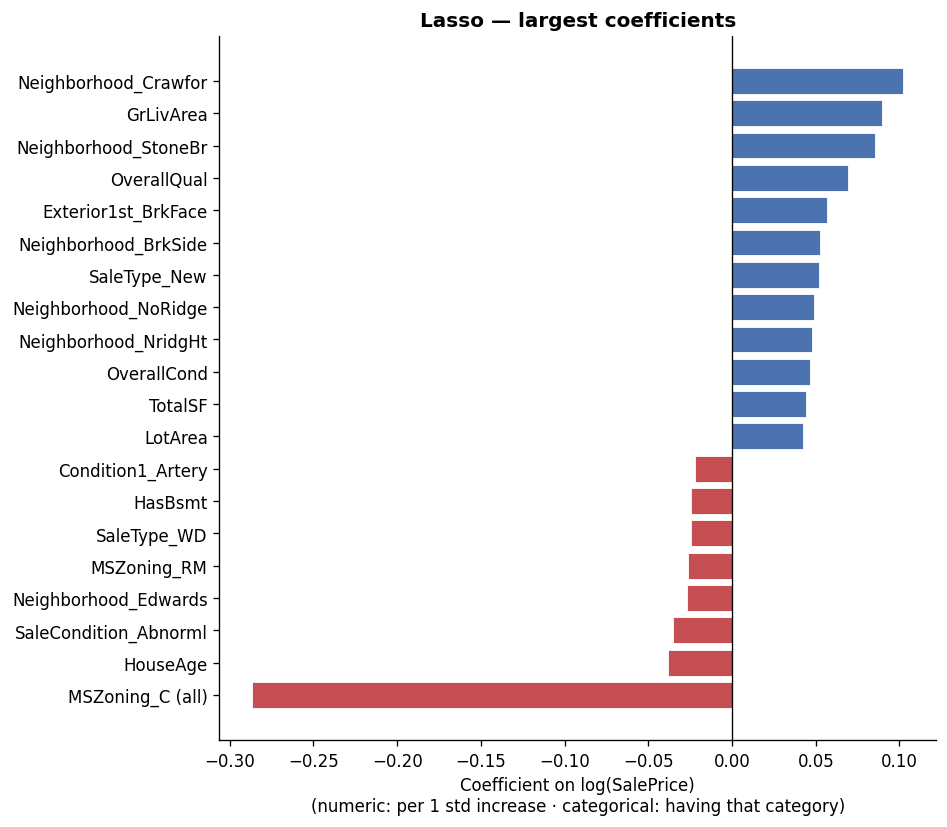

In [5]:
lasso = make_lasso().fit(X, y)
coefs = pd.Series(lasso.named_steps['model'].coef_,
                  index=lasso.named_steps['prep'].named_steps['columns'].get_feature_names_out())
print(f'Lasso keeps {(coefs != 0).sum()} of {len(coefs)} features')

top = pd.concat([coefs.nsmallest(8), coefs.nlargest(12)]).sort_values()
fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(top.index, top.values, color=['#C44E52' if v < 0 else '#4C72B0' for v in top.values],
        edgecolor='white', linewidth=0.5)
ax.axvline(0, color='black', linewidth=0.8)
ax.set_xlabel('Coefficient on log(SalePrice)\n(numeric: per 1 std increase · categorical: having that category)')
ax.set_title('Lasso — largest coefficients', fontweight='bold')
plt.tight_layout()
plt.show()

Reading the coefficients (a coefficient *c* on the log scale ≈ a price change of *e*<sup>c</sup> − 1):
- **Location** dominates the categorical effects: being in *Crawford* or *StoneBrook* adds ~9–11% to the price; commercial zoning (`MSZoning_C`) subtracts ~25%.
- **Size and quality** (`GrLivArea`, `OverallQual`, `TotalSF`) are the strongest numeric drivers, consistent with the EDA.
- **Sale conditions** matter: new houses (`SaleType_New`) sell higher, abnormal sales (foreclosures, short sales) lower.
- Some signs are counter-intuitive (e.g. `HasBsmt` < 0). This is a side effect of correlated features: `HasBsmt` and `TotalBsmtSF` share information, so their coefficients must be read together. **Coefficients describe the model, not causal effects.**

## 3. Tree-based models
Hyperparameters follow a conservative setup for a small dataset: many shallow trees, low learning rate and row/column subsampling to limit overfitting.

In [6]:
evaluate('Random Forest', with_preprocessing(
    RandomForestRegressor(n_estimators=300, max_features=0.3, n_jobs=-1, random_state=42)))
evaluate('LightGBM', make_lgbm())
evaluate('XGBoost', make_xgb())

Random Forest          RMSE 0.1290 ± 0.0077   (2.5s)
LightGBM               RMSE 0.1147 ± 0.0087   (4.8s)
XGBoost                RMSE 0.1108 ± 0.0064   (11.0s)


Gradient boosting (LightGBM, XGBoost) clearly beats Random Forest, and XGBoost matches the best linear model. Two very different families reaching the same error suggests they make **different mistakes**, which is exactly when ensembling helps.

## 4. Ensembles
- **Voting**: simple average of the predictions.
- **Stacking**: a Ridge meta-model learns how to weight each base model from out-of-fold predictions.

In [7]:
base = [('lasso', make_lasso()), ('ridge', make_ridge()), ('xgb', make_xgb()), ('lgbm', make_lgbm())]

evaluate('Voting (4 models)', VotingRegressor(base))
evaluate('Stacking (4 models)', StackingRegressor(base, final_estimator=Ridge(alpha=1), cv=5, n_jobs=-1))
evaluate('Voting (Lasso + XGB)', make_final_model())

Voting (4 models)      RMSE 0.1081 ± 0.0073   (15.9s)
Stacking (4 models)    RMSE 0.1077 ± 0.0073   (40.3s)
Voting (Lasso + XGB)   RMSE 0.1070 ± 0.0066   (12.5s)


## 5. Comparison

In [8]:
summary = (pd.DataFrame({'RMSE (mean)': {k: v.mean() for k, v in results.items()},
                         'RMSE (std)': {k: v.std() for k, v in results.items()}})
           .sort_values('RMSE (mean)'))
summary['vs. baseline'] = (1 - summary['RMSE (mean)'] / summary.loc['Median (dummy)', 'RMSE (mean)']).map('{:.0%}'.format)
summary.round(4)

,RMSE (mean),RMSE (std),vs. baseline
Voting (Lasso + XGB),0.1070,0.0066,73%
Stacking (4 models),0.1077,0.0073,73%
Voting (4 models),0.1081,0.0073,73%
Lasso,0.1106,0.0065,72%
ElasticNet,0.1107,0.0067,72%
XGBoost,0.1108,0.0064,72%
Ridge,0.1127,0.0075,72%
LightGBM,0.1147,0.0087,71%
Random Forest,0.1290,0.0077,68%
Linear Regression,0.2090,0.1473,48%


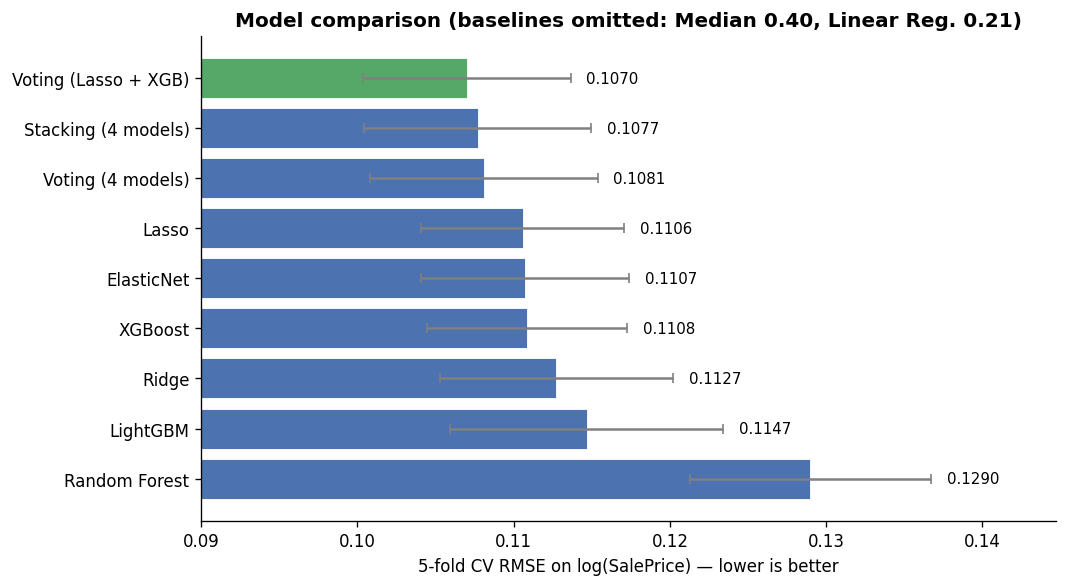

In [9]:
plot = summary.drop(['Median (dummy)', 'Linear Regression']).sort_values('RMSE (mean)', ascending=False)
best = plot.index[-1]

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(plot.index, plot['RMSE (mean)'], xerr=plot['RMSE (std)'],
        color=['#55A868' if n == best else '#4C72B0' for n in plot.index],
        edgecolor='white', linewidth=0.5, error_kw={'ecolor': 'gray', 'capsize': 3})
for i, (v, s) in enumerate(zip(plot['RMSE (mean)'], plot['RMSE (std)'])):
    ax.text(v + s + 0.001, i, f'{v:.4f}', va='center', fontsize=9)
ax.set_xlim(0.09, (plot['RMSE (mean)'] + plot['RMSE (std)']).max() + 0.008)
ax.set_xlabel('5-fold CV RMSE on log(SalePrice) — lower is better')
ax.set_title('Model comparison (baselines omitted: Median 0.40, Linear Reg. 0.21)', fontweight='bold')
plt.tight_layout()
plt.show()

**Selected model: Voting (Lasso + XGBoost).**
- Best CV score, with the simplest ensemble: two models, plain average, no meta-model.
- Combines a linear model (good at extrapolating smooth trends such as size → price) with a tree model (captures thresholds and interactions).
- Stacking 4 models is not better and is ~4x slower to train.

*Caveat:* the differences between the top models (~0.001–0.003) are smaller than the fold-to-fold std, and picking the best of several options on the same folds is slightly optimistic. The real test is the Kaggle leaderboard, computed on unseen data.

## 6. Train on all data and predict the test set

In [10]:
final_model = make_final_model().fit(X, y)

pred_test = np.expm1(final_model.predict(test))   # back from log scale to USD

Path('../models').mkdir(exist_ok=True)
Path('../submissions').mkdir(exist_ok=True)
joblib.dump(final_model, '../models/final_model.joblib')
submission = pd.DataFrame({'Id': test['Id'], 'SalePrice': pred_test})
submission.to_csv('../submissions/submission.csv', index=False)

print('Saved models/final_model.joblib and submissions/submission.csv')
submission['SalePrice'].describe().round(0)

Saved models/final_model.joblib and submissions/submission.csv


count      1459.0
mean     178382.0
std       77928.0
min       39309.0
25%      126874.0
50%      157048.0
75%      210769.0
max      818881.0
Name: SalePrice, dtype: float64

Test predictions have a distribution very close to the training prices (median ~$160k), a good sign that nothing went wrong.

## 7. Summary

| Model | CV RMSE |
|---|---|
| Median baseline | 0.400 |
| Linear Regression | 0.209 (unstable) |
| Best regularized linear (Lasso) | 0.111 |
| Best tree model (XGBoost) | 0.111 |
| **Voting Lasso + XGBoost (final)** | **0.107** |

The final model reduces the baseline error by ~73%, i.e. a typical error of ~11% on the sale price.

**Next:** `04_evaluation.ipynb`: residual analysis, errors in dollars and model interpretation with SHAP.